In [1]:
import os
import numpy as np
import cv2

Access to the files

In [2]:
subfolder_path='./stripes_photos'
files = [f for f in os.listdir(subfolder_path) if f.endswith(('.png', '.jpg', '.jpeg'))]


Conversion to Grayscale and Pixel Reading

In [3]:
pixel_data_list=[]
greyscale_images=[]
for file_name in files:
    file_path=os.path.join(subfolder_path, file_name)
    image=cv2.imread(file_path)
    grey_photo=cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    greyscale_images.append(grey_photo)
    img_grey=cv2.imread(file_path,0)  #Reading the images in greyscale mode
    pixel_data_list.append(img_grey)
    print(f"Processed: {file_name}, Shape: {img_grey.shape}")
    #Thus created 50 numpy arrays of pixelvalues

Processed: IMG_20260327_183257_Burst01.jpg, Shape: (3072, 4096)
Processed: IMG_20260327_183257_Burst02.jpg, Shape: (3072, 4096)
Processed: IMG_20260327_183257_Burst03.jpg, Shape: (3072, 4096)
Processed: IMG_20260327_183257_Burst04.jpg, Shape: (3072, 4096)
Processed: IMG_20260327_183257_Burst05.jpg, Shape: (3072, 4096)
Processed: IMG_20260327_183257_Burst06.jpg, Shape: (3072, 4096)
Processed: IMG_20260327_183257_Burst07.jpg, Shape: (3072, 4096)
Processed: IMG_20260327_183257_Burst08.jpg, Shape: (3072, 4096)
Processed: IMG_20260327_183257_Burst09.jpg, Shape: (3072, 4096)
Processed: IMG_20260327_183257_Burst10.jpg, Shape: (3072, 4096)
Processed: IMG_20260327_183259_Burst01.jpg, Shape: (3072, 4096)
Processed: IMG_20260327_183259_Burst02.jpg, Shape: (3072, 4096)
Processed: IMG_20260327_183259_Burst03.jpg, Shape: (3072, 4096)
Processed: IMG_20260327_183259_Burst04.jpg, Shape: (3072, 4096)
Processed: IMG_20260327_183259_Burst05.jpg, Shape: (3072, 4096)
Processed: IMG_20260327_183259_Burst06.j

Sample Grayscale Image

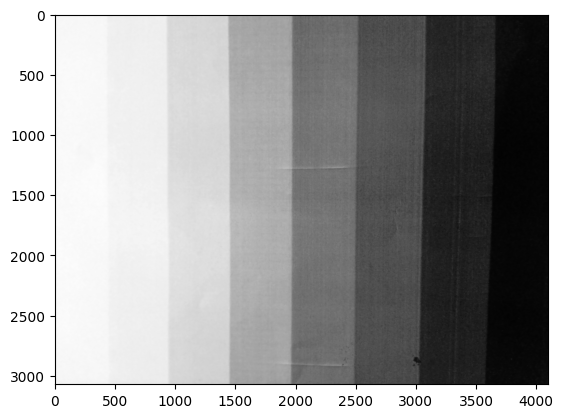

In [4]:
import matplotlib.pyplot as plt
plt.imshow(greyscale_images[2], cmap='gray')
plt.show()

Pixel Value Analysis

In [5]:
greyscale_images_stack= np.stack(greyscale_images, axis=0)
# All the analysis will produce a single 4096*3072 numpy array of a representative photo
mean_pixel_value=np.mean(greyscale_images_stack, axis=0)
min_pixel_value=np.min(greyscale_images_stack, axis=0)
max_pixel_value=np.max(greyscale_images_stack, axis=0)

Results

In [6]:
print(mean_pixel_value)
print(min_pixel_value)
print(max_pixel_value)

[[179.82 179.38 179.26 ...  19.84  20.68  21.08]
 [177.98 178.2  178.7  ...  20.02  20.52  20.6 ]
 [178.72 178.28 178.38 ...  19.46  19.8   19.66]
 ...
 [229.32 229.2  229.24 ...  21.48  22.14  23.14]
 [229.46 229.3  229.16 ...  22.8   23.44  24.44]
 [229.46 229.32 229.12 ...  22.68  23.72  24.9 ]]
[[114 115 110 ...  12  11  10]
 [110 114 113 ...  12  10   9]
 [114 118 115 ...  13  12  11]
 ...
 [169 172 179 ...  14  14  13]
 [170 172 173 ...  12  12  12]
 [169 175 173 ...  12  12  12]]
[[237 236 234 ...  35  40  48]
 [236 235 234 ...  34  33  37]
 [235 234 234 ...  31  28  28]
 ...
 [234 234 234 ...  73  74  91]
 [235 234 234 ...  73  67  65]
 [235 235 235 ...  70  71  65]]


Variance Analysis

In [7]:
variance_pixel_value=np.var(greyscale_images_stack, axis=0)
var_min=np.min(variance_pixel_value)
var_max=np.max(variance_pixel_value)
print(var_min)
print(var_max)
var_mean=np.mean(variance_pixel_value)
print(var_mean)
#These calculations are on that so called 'Representative Grayscale Image' of proper dimensions
#Another Note is that this cell will take a little time.

0.14760000000000018
2899.889600000001
29.441059238370258


Dimensions(for information purposes only)

In [8]:
greyscale_images_stack.shape

(50, 3072, 4096)

Detecting Regions with High Variance of Pixel Values

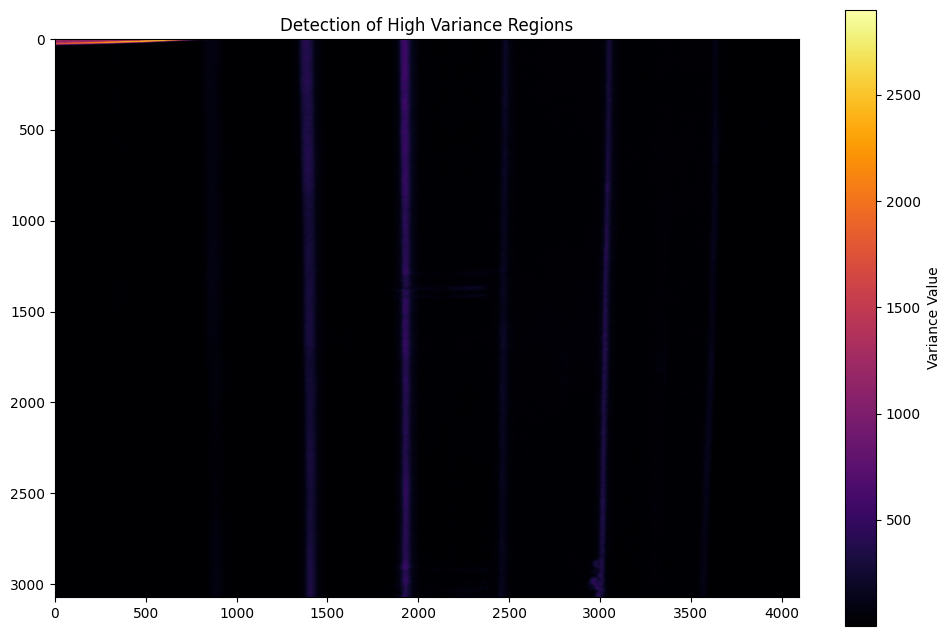

In [9]:
plt.figure(figsize=(12,8))
plt.imshow(variance_pixel_value, cmap='inferno', vmin=var_min, vmax=var_max)
plt.colorbar(label='Variance Value')
plt.title("Detection of High Variance Regions")
plt.show()


Variance Anomally with Pixel Values

Distinguishing the Stripes( The Histogram Approach)

In [10]:


# 1. Average across rows to get a clean 1D profile of the stripes
column_average = np.mean(mean_pixel_value, axis=0)

# 2. Calculate the difference between adjacent columns
# Large values here indicate a change in stripe
diffs = np.abs(np.diff(column_average))

# 3. Identify boundary indices where the jump is significant
# Adjust 'threshold' based on your specific image's contrast
threshold = 1
boundary_indices = np.where(diffs > threshold)[0]


In [11]:
print(boundary_indices)

[1904 1907 1909 1910 1912 1913 1915 2464 3032 3040]


The Peaks of the Histogram

Text(0, 0.5, 'Frequency (Number of Columns)')

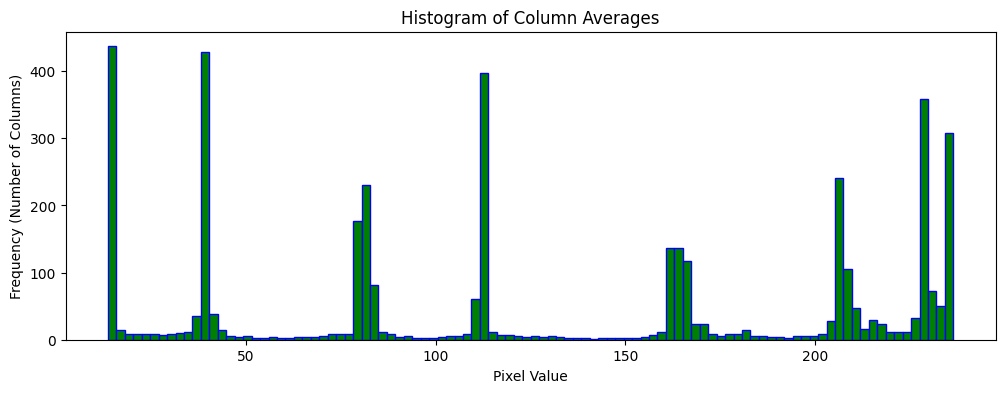

In [12]:
plt.figure(figsize=(12,4))
plt.hist(column_average, bins=100, color='green', edgecolor='blue')
plt.title("Histogram of Column Averages")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency (Number of Columns)")


Text(0, 0.5, 'Frequency (Number of Columns)')

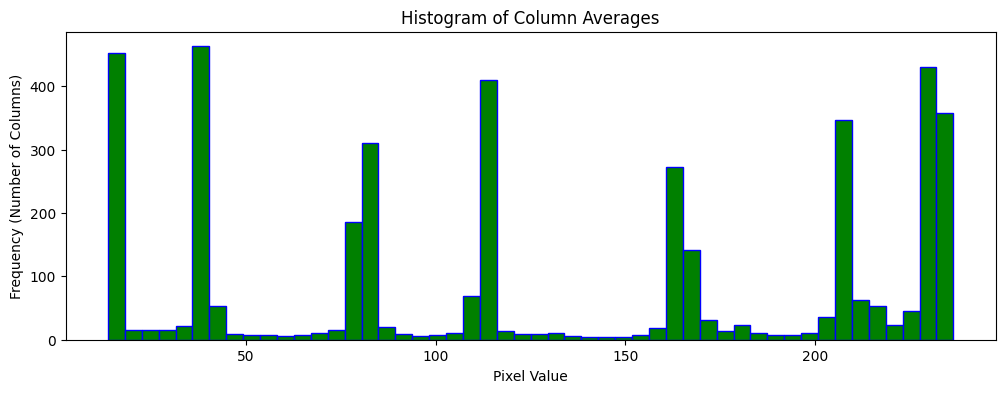

In [13]:
plt.figure(figsize=(12,4))
plt.hist(column_average, bins=50, color='green', edgecolor='blue')
plt.title("Histogram of Column Averages")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency (Number of Columns)")


Variance Distinction (Numerical Part)

In [14]:
#Accessing the Coordinates with pixel value > 200
coordinates_geq200= np.argwhere(mean_pixel_value > 200)

# Calculating the variance of the whitish shades
variance_pixel_value_geq200=[]
for i in coordinates_geq200:
    variance_pixel_value_geq200.append(variance_pixel_value[i[0], i[1]])

print(np.mean(variance_pixel_value_geq200))
print(np.min(variance_pixel_value_geq200))
print(np.max(variance_pixel_value_geq200))

12.116352632503185
0.14760000000000018
2621.08


In [15]:
#Accessing the Coordinates with pixel value <130
coordinates_leq130= np.argwhere(mean_pixel_value <130)

# Calculating the variance of the blackish shades
variance_pixel_value_leq130=[]
for i in coordinates_leq130:
    variance_pixel_value_leq130.append(variance_pixel_value[i[0], i[1]])

print(np.mean(variance_pixel_value_leq130))
print(np.min(variance_pixel_value_leq130))
print(np.max(variance_pixel_value_leq130))

30.2984380612775
0.2799999999999996
638.7443999999998


In [16]:
mean_pixel_value_leq130=[]
for i in coordinates_leq130:
    mean_pixel_value_leq130.append(mean_pixel_value[i[0], i[1]])

mean_pixel_value_geq200=[]
for i in coordinates_geq200:
    mean_pixel_value_geq200.append(mean_pixel_value[i[0], i[1]])

Relative Variance

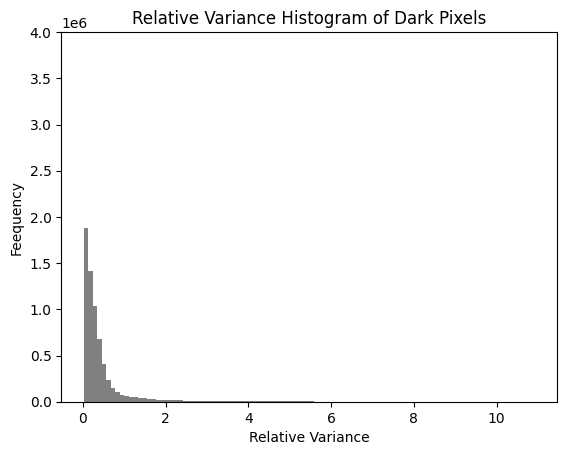

In [35]:
relative_variance_leq130= [x/y for x, y in zip(variance_pixel_value_leq130, mean_pixel_value_leq130)]
plt.hist(relative_variance_leq130, bins=100, color='grey')
plt.ylim(0, 4000000)
plt.title('Relative Variance Histogram of Dark Pixels')
plt.xlabel('Relative Variance')
plt.ylabel('Feequency')
plt.show()

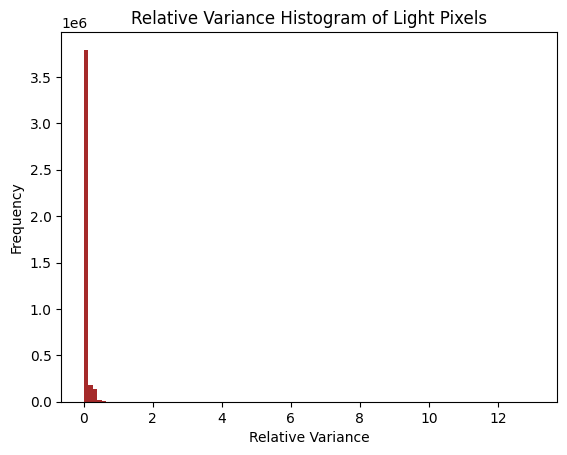

In [18]:
relative_variance_geq200= [x/y for x, y in zip(variance_pixel_value_geq200, mean_pixel_value_geq200)]
plt.hist(relative_variance_geq200, bins=100, color='brown')
plt.title('Relative Variance Histogram of Light Pixels')
plt.xlabel('Relative Variance')
plt.ylabel('Frequency')
plt.show()

Variance Across Regions

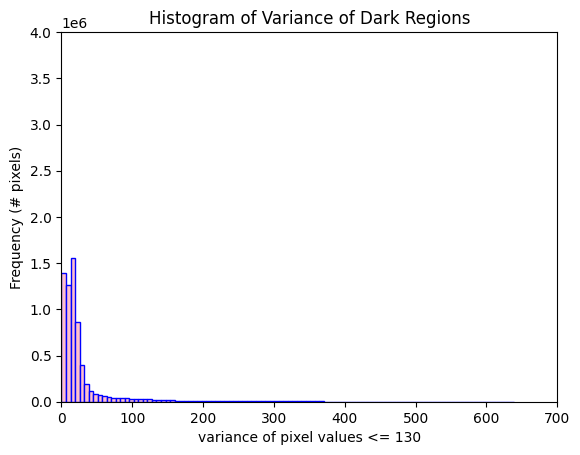

In [40]:
plt.hist(variance_pixel_value_leq130, bins=100, color='pink', edgecolor='blue')
plt.ylim(0, 4000000)
plt.xlim(0, 700)
plt.xlabel('variance of pixel values <= 130')
plt.ylabel('Frequency (# pixels)')
plt.title('Histogram of Variance of Dark Regions')
plt.show()

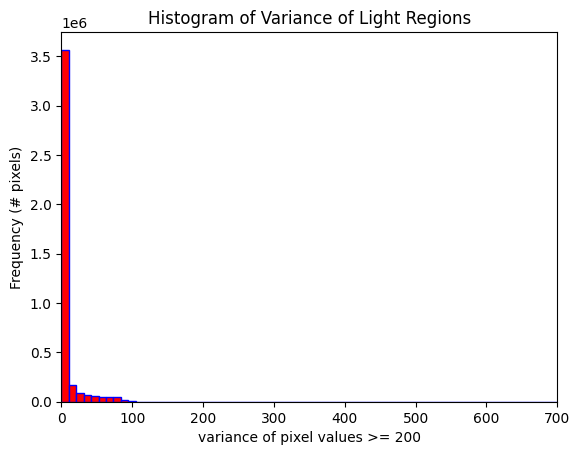

In [ ]:
plt.hist(variance_pixel_value_geq200, bins=250, color='red', edgecolor='blue')
plt.xlim(0, 700)  # To compare properly at the same scale with the darker regions, higher variances are ignored.
plt.xlabel('variance of pixel values >= 200')
plt.ylabel('Frequency (# pixels)')
plt.title('Histogram of Variance of Light Regions')
plt.show()
# Bin size anomaly is to divide the x range into intervals of almost same length as that of dark pixels

Hence the black regions have higher variability than the whiter regions in terms of pixel values

2D Histogram Plotting Mean Pixel Values vs Variance

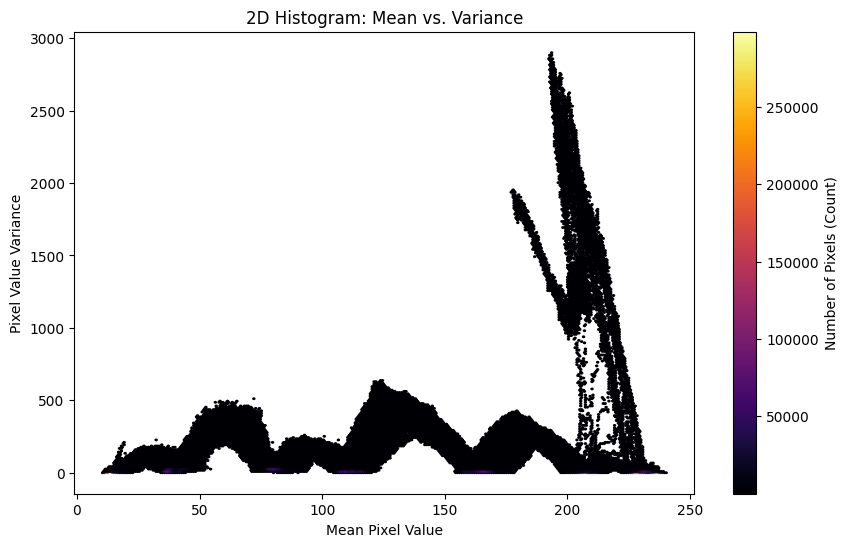

In [21]:
# 2. Flatten the arrays to 1D
# This ensures that each pixel's mean is paired with its specific variance
x = mean_pixel_value.flatten()
y = variance_pixel_value.flatten()

# 3. Create the 2D Histogram / Hexbin Plot
plt.figure(figsize=(10, 6))

# 'gridsize' controls the resolution; 'cmap' sets the color scheme
hb = plt.hexbin(x, y, gridsize=300, cmap='inferno', mincnt=1)

# Add aesthetics
plt.colorbar(hb, label='Number of Pixels (Count)')
plt.xlabel('Mean Pixel Value')
plt.ylabel('Pixel Value Variance')
plt.title('2D Histogram: Mean vs. Variance')

plt.show()

Masked Heatmap of Variance

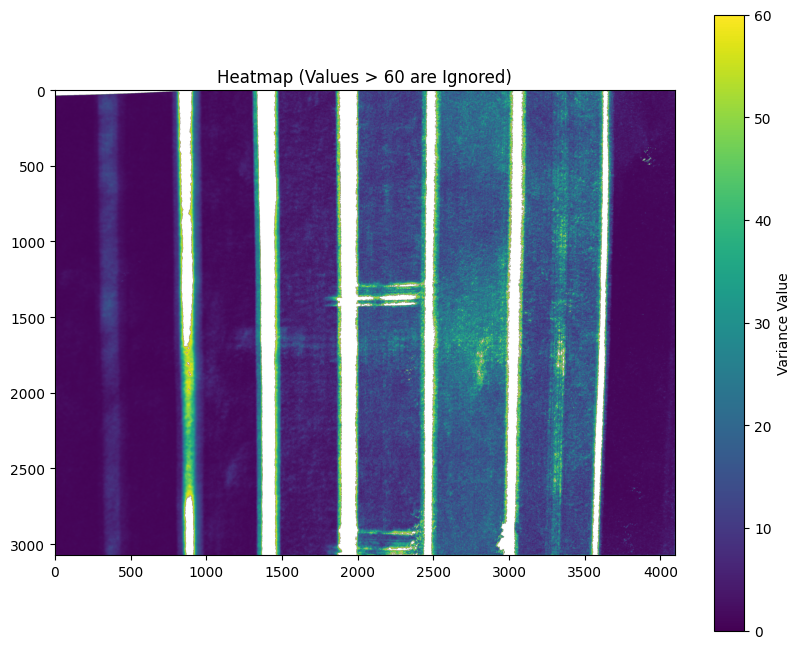

In [22]:
# Announcing a threshold variance for mask
threshold=60


# 2. Create a masked array where values > threshold are ignored
masked_variance_pixel_value = np.ma.masked_where(variance_pixel_value > threshold, variance_pixel_value)

# 3. Plot using Seaborn's heatmap
plt.figure(figsize=(10, 8))

# THE COLORMAP IS SPECIFIED HERE:
plt.imshow(masked_variance_pixel_value, cmap="viridis", vmin=0, vmax=threshold) 
plt.colorbar(label='Variance Value')
plt.title(f"Heatmap (Values > {threshold} are Ignored)")
plt.show()

Histogram of Variance of Pixel Values

In [23]:
print(np.min(variance_pixel_value))
print(np.max(variance_pixel_value))

0.14760000000000018
2899.889600000001


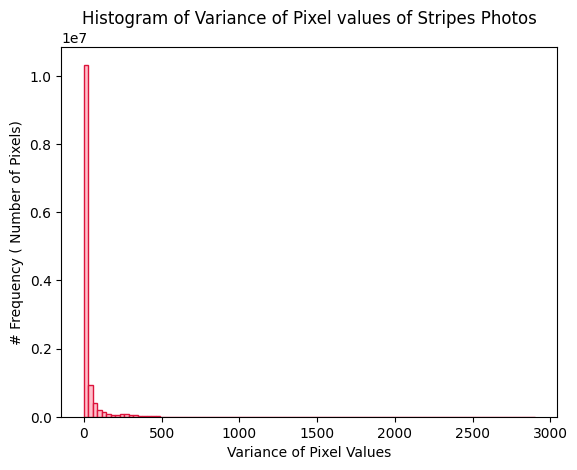

In [24]:
plt.hist(variance_pixel_value.ravel(), bins=100, range=[0,2900], color='pink', edgecolor='crimson')
plt.title('Histogram of Variance of Pixel values of Stripes Photos')
plt.xlabel('Variance of Pixel Values')
plt.ylabel('# Frequency ( Number of Pixels)')
plt.show()

Slightly Modified version of the 2d histogram

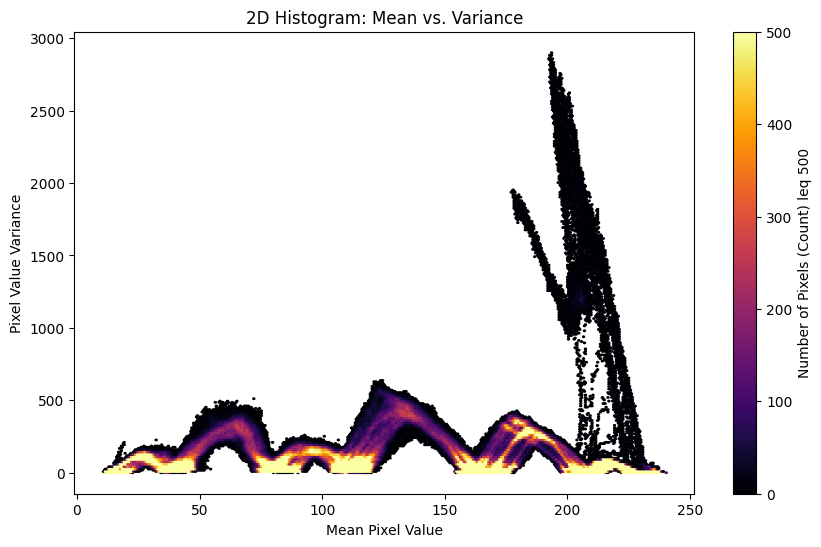

In [25]:
# 2. Flatten the arrays to 1D
# This ensures that each pixel's mean is paired with its specific variance
x = mean_pixel_value.flatten()
y = variance_pixel_value.flatten()

# 3. Create the 2D Histogram / Hexbin Plot
plt.figure(figsize=(10, 6))

# 'gridsize' controls the resolution; 'cmap' sets the color scheme
hb = plt.hexbin(x, y, gridsize=300, cmap='inferno', mincnt=1, vmin=0, vmax=500)

# Add aesthetics
plt.colorbar(hb, label='Number of Pixels (Count) leq 500')
plt.xlabel('Mean Pixel Value')
plt.ylabel('Pixel Value Variance')
plt.title('2D Histogram: Mean vs. Variance')

plt.show()

Detecting Outliers

Number of high-variance pixels: 15661


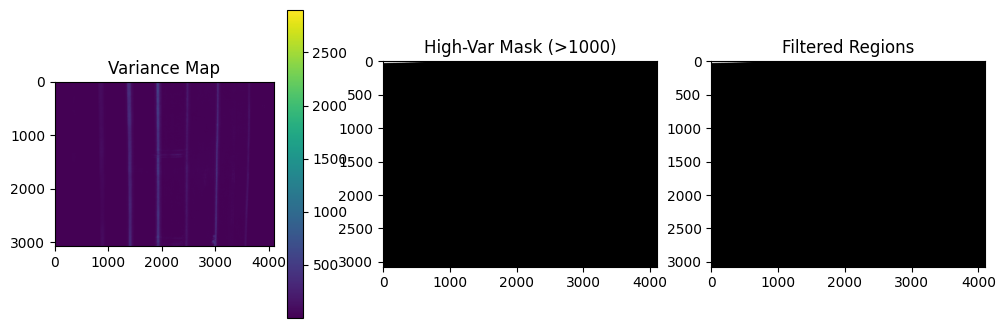

In [26]:
threshold_2=1000
# 3. Create the Mask: Identify regions where variance > threshold
# This returns a boolean array where True is high variance
high_var_mask = variance_pixel_value > threshold_2

# 4. Apply mask to the mean map (or original image)
# Option A: Create a new image keeping only high variance areas
high_var_regions = np.where(high_var_mask, mean_pixel_value, 0)

# Option B: Get coordinates (y, x) of high variance pixels
high_var_pixels = np.argwhere(high_var_mask)
print(f"Number of high-variance pixels: {len(high_var_pixels)}")

# 5. Visualization
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.title("Variance Map")
plt.imshow(variance_pixel_value, cmap='viridis')
plt.colorbar()

plt.subplot(1, 3, 2)
plt.title("High-Var Mask (>1000)")
plt.imshow(high_var_mask, cmap='gray')

plt.subplot(1, 3, 3)
plt.title("Filtered Regions")
plt.imshow(high_var_regions, cmap='gray')
plt.show()

Text(0.5, 1.0, 'Detecting regions with variance >= 1000')

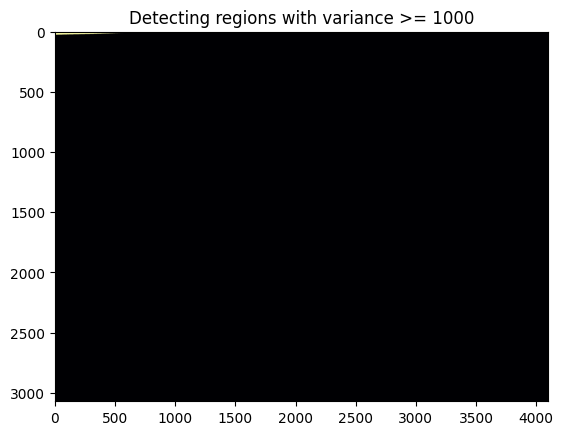

In [27]:
plt.imshow(high_var_mask, cmap='inferno')
plt.title('Detecting regions with variance >= 1000')

Ignoring the Outliers

Original shape: (3072, 4096)
Filtered points: (12567251,)


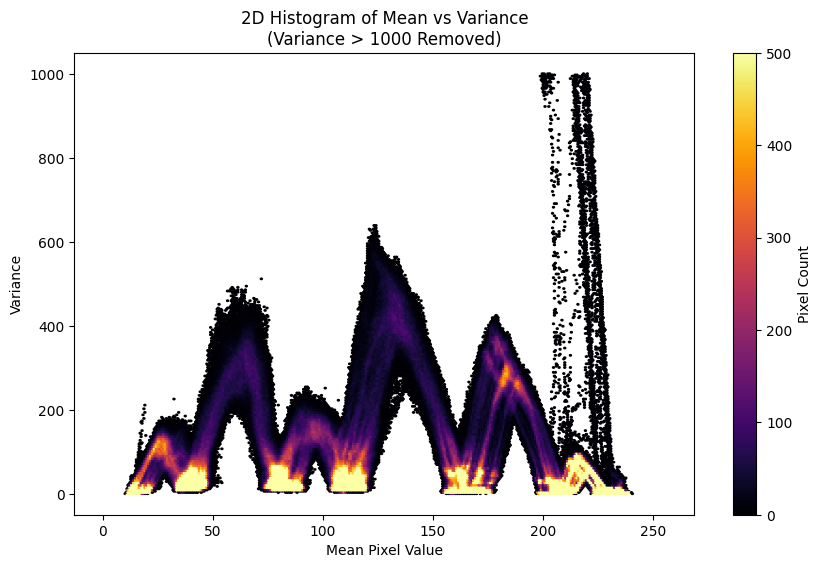

In [28]:
mask = variance_pixel_value <= threshold_2

# Apply mask to keep only valid data points
filtered_mean = mean_pixel_value[mask]
filtered_variance = variance_pixel_value[mask]

print(f"Original shape: {mean_pixel_value.shape}")
print(f"Filtered points: {filtered_mean.shape}")

# --- 4. Plot 2D Histogram Without Outliers ---
plt.figure(figsize=(10, 6))
hb_2=plt.hexbin(
    filtered_mean.flatten(), 
    filtered_variance.flatten(), 
    gridsize= 300 ,
    extent=(0, 256, 0, 1000) ,
    cmap='inferno',
    mincnt=1 ,
    vmin=0 ,
    vmax=500
)

plt.colorbar(hb_2, label='Pixel Count')
plt.title(f'2D Histogram of Mean vs Variance\n(Variance > {threshold_2} Removed)')
plt.xlabel('Mean Pixel Value')
plt.ylabel('Variance')
plt.show()

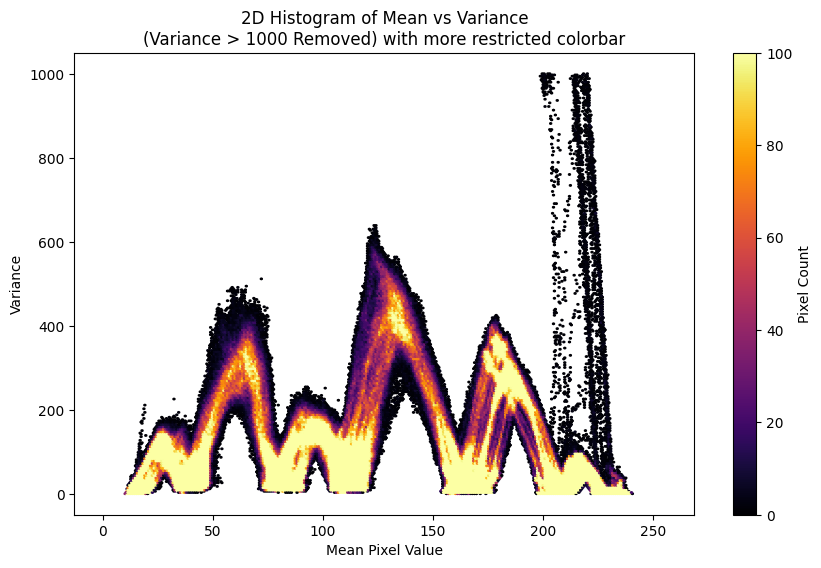

In [29]:
plt.figure(figsize=(10, 6))
hb_3=plt.hexbin(
    filtered_mean.flatten(), 
    filtered_variance.flatten(), 
    gridsize= 300 ,
    extent=(0, 256, 0, 1000) ,
    cmap='inferno',
    mincnt=1 ,
    vmin=0 ,
    vmax=100
)

plt.colorbar(hb_3, label='Pixel Count')
plt.title(f'2D Histogram of Mean vs Variance\n(Variance > {threshold_2} Removed) with more restricted colorbar')
plt.xlabel('Mean Pixel Value')
plt.ylabel('Variance')
plt.show()

Working with The Filtered Lists to Count out the boundary regions

In [30]:
type(filtered_variance)

numpy.ndarray

In [31]:
type(filtered_mean)

numpy.ndarray

In [32]:
# This works for the black regions that count out the boundary regions
coordinates_filtered_leq130= np.argwhere(filtered_mean <130)

# Calculating the variance of the blackish shades
variance_filtered_pixel_value_leq130=[]
for i in coordinates_filtered_leq130:
    variance_filtered_pixel_value_leq130.append(filtered_variance[i])

print(np.mean(variance_filtered_pixel_value_leq130))
print(np.min(variance_filtered_pixel_value_leq130))
print(np.max(variance_filtered_pixel_value_leq130))

30.2984380612775
0.2799999999999996
638.7443999999998


In [33]:
coordinates_filtered_geq200= np.argwhere(filtered_mean > 200)

# Calculating the variance of the whitish shades
variance_filtered_pixel_value_geq200=[]
for i in coordinates_filtered_geq200:
    variance_filtered_pixel_value_geq200.append(filtered_variance[i])

print(np.mean(variance_filtered_pixel_value_geq200))
print(np.min(variance_filtered_pixel_value_geq200))
print(np.max(variance_filtered_pixel_value_geq200))

8.060149502553541
0.14760000000000018
999.8595999999998
